# Laboratorium 3 — Otwarte dane i wartości odstające

**Eksploracja danych** · dr Paweł Gliwny · WFiIS UŁ

Na tych zajęciach:

1. **Część 1** — pobierzesz dane z portalu otwartych danych Łodzi, wczytasz je, zmienisz ich format, policzysz statystyki zbiorcze i zrobisz proste wykresy.
2. **Część 2** — na danych o pacjentach przejdziesz kolejne kroki wykrywania wartości odstających: od najprostszych do bardziej złożonych.

Miejsca do uzupełnienia oznaczone są `# TODO`. Odpowiedzi na pytania wpisuj w komórkach tekstowych oznaczonych ✍️.

> Notatnik po zajęciach umieść w swoim repozytorium na GitHubie.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.float_format", "{:.2f}".format)
plt.rcParams["figure.dpi"] = 100

In [2]:
def upewnij_sie_ze_jest(nazwa_pliku):
    # W Colabie: jeśli pliku nie ma, otwiera okno wgrywania pliku.
    if Path(nazwa_pliku).exists():
        print(f"Plik {nazwa_pliku} jest na miejscu.")
        return
    try:
        from google.colab import files
        print(f"Wgraj plik {nazwa_pliku}:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Umieść plik {nazwa_pliku} w folderze z notatnikiem.")

---
# Część 1. Dane z portalu otwartych danych Łodzi

Portal: [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl)

Zaczynamy od wspólnego przykładu — pliku `szkolnictwo_wysze.csv` (szkolnictwo wyższe w Łodzi w latach 2012–2024). Pobierz go z portalu albo od prowadzącego i wgraj do Colaba (ikona folderu po lewej lub komórka poniżej).

In [4]:
PLIK_LODZ = "szkolnictwo_wysze.csv"
upewnij_sie_ze_jest(PLIK_LODZ)

Plik szkolnictwo_wysze.csv jest na miejscu.


## 1.1 Wczytanie danych

Zanim wywołasz `read_csv`, obejrzyj surowy plik — pierwsze linie tekstu powiedzą, jaki jest separator.

In [6]:
# podgląd surowego pliku
with open(PLIK_LODZ, encoding="utf-8") as f:
    for _ in range(5):
        print(f.readline().rstrip())

﻿name;rok;wartość;zmienna
Szkolnictwo wyższe;2012;22;uczelnie
Szkolnictwo wyższe;2013;22;uczelnie
Szkolnictwo wyższe;2014;23;uczelnie
Szkolnictwo wyższe;2015;21;uczelnie


In [7]:
# Wczytanie z separatorem ';' i kodowaniem utf-8
df = pd.read_csv(PLIK_LODZ, sep=';', encoding='utf-8-sig')

display(df.head())
print("Kształt:", df.shape)
df.info()


Kształt: (65, 4)
<class 'pandas.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   name     65 non-null     str  
 1   rok      65 non-null     int64
 2   wartość  65 non-null     int64
 3   zmienna  65 non-null     str  
dtypes: int64(2), str(2)
memory usage: 2.2 KB


,name,rok,wartość,zmienna
0,Szkolnictwo wyższe,2012,22,uczelnie
1,Szkolnictwo wyższe,2013,22,uczelnie
2,Szkolnictwo wyższe,2014,23,uczelnie
3,Szkolnictwo wyższe,2015,21,uczelnie
4,Szkolnictwo wyższe,2016,20,uczelnie


✍️ **Pytanie:** Jaki jest separator? Czy kolumna `wartość` ma typ liczbowy? Czy nazwy kolumn z polskimi znakami wczytały się poprawnie?

*Odpowiedź:* Separator w pliku to średnik (`;`). Kolumna `wartość` ma poprawny typ liczbowy całkowity (`int64`), a polskie znaki w nagłówkach wczytały się prawidłowo dzięki kodowaniu UTF-8.


## 1.2 Format długi czy szeroki?

Przypomnienie z wykładu 2: w formacie **długim** każdy wiersz to jedna para (zmienna, wartość); w formacie **szerokim** każda zmienna ma własną kolumnę.

1. Sprawdź, jakie wartości przyjmuje kolumna `zmienna` i ile razy każda występuje.
2. Przekształć dane do formatu szerokiego: wiersze = lata, kolumny = zmienne.

In [10]:
# Zmienne i liczba wierszy
print(df['zmienna'].value_counts())

# Format szeroki (pivot)
szeroka = df.pivot(index='rok', columns='zmienna', values='wartość')
display(szeroka)


zmienna
uczelnie             13
ogółem               13
kobiety              13
mężczyźni            13
absolwenci ogółem    13
Name: count, dtype: int64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
rok,,,,,
2012,24825,55265,36281,91546,22
2013,22590,50007,33464,83471,22
2014,21343,48220,32456,80676,23
2015,19835,45584,30769,76353,21
2016,17662,44053,29908,73961,20
2017,19281,42990,29029,72019,22
2018,17046,39312,26253,65565,20
2019,15819,38146,26297,64443,19
2020,14082,39170,26155,65325,18


## 1.3 Czy dane są spójne?

Liczba studentów `ogółem` powinna być sumą `kobiety` i `mężczyźni`. Sprawdź to dla każdego roku.

In [12]:
# Sprawdzenie: (kobiety + mężczyźni) - ogółem
roznica = (szeroka['kobiety'] + szeroka['mężczyźni']) - szeroka['ogółem']
print("Różnica dla każdego roku:")
print(roznica)
# W każdym roku różnica wynosi 0, więc dane są całkowicie spójne.


Różnica dla każdego roku:
rok
2012    0
2013    0
2014    0
2015    0
2016    0
2017    0
2018    0
2019    0
2020    0
2021    0
2022    0
2023    0
2024    0
dtype: int64


## 1.4 Statystyki zbiorcze

1. Policz statystyki opisowe dla wszystkich zmiennych (`describe`).
2. O ile procent zmieniła się każda zmienna między 2012 a 2024 rokiem?
3. Dodaj kolumnę `udzial_kobiet` (udział kobiet wśród studentów) i kolumnę `studenci_na_uczelnie`.

In [14]:
# 1. Statystyki opisowe
display(szeroka.describe())

# 2. Zmiana procentowa 2012 -> 2024
zmiana = ((szeroka.loc[2024] - szeroka.loc[2012]) / szeroka.loc[2012]) * 100
print("Zmiana procentowa 2012 -> 2024 [%]:")
print(zmiana.round(1))

# 3. Nowa kolumna: udział kobiet
szeroka['udzial_kobiet'] = szeroka['kobiety'] / szeroka['ogółem']
display(szeroka[['ogółem', 'kobiety', 'udzial_kobiet']])


Zmiana procentowa 2012 -> 2024 [%]:
zmienna
absolwenci ogółem   -41.30
kobiety             -30.20
mężczyźni           -29.10
ogółem              -29.80
uczelnie            -31.80
dtype: float64


zmienna,absolwenci ogółem,kobiety,mężczyźni,ogółem,uczelnie
count,13.00,13.00,13.00,13.00,13.00
mean,17780.54,43010.92,28793.92,71804.85,19.54
std,3522.40,5391.05,3524.63,8900.65,2.44
min,14082.00,38146.00,25710.00,64272.00,15.00
25%,14756.00,39170.00,26049.00,65297.00,18.00
50%,17046.00,39958.00,26297.00,66002.00,20.00
75%,19835.00,45584.00,30769.00,76353.00,22.00
max,24825.00,55265.00,36281.00,91546.00,23.00


zmienna,ogółem,kobiety,udzial_kobiet
rok,,,
2012,91546,55265,0.60
2013,83471,50007,0.60
2014,80676,48220,0.60
2015,76353,45584,0.60
2016,73961,44053,0.60
2017,72019,42990,0.60
2018,65565,39312,0.60
2019,64443,38146,0.59
2020,65325,39170,0.60


## 1.5 Wykresy

Narysuj trzy wykresy (najlepiej obok siebie, `plt.subplots(1, 3)`):

1. liczba studentów w czasie — osobne linie dla kobiet i mężczyzn,
2. liczba uczelni w czasie,
3. udział kobiet wśród studentów (oś Y od 0 do 1).

Każdy wykres podpisz: tytuł, opisy osi.

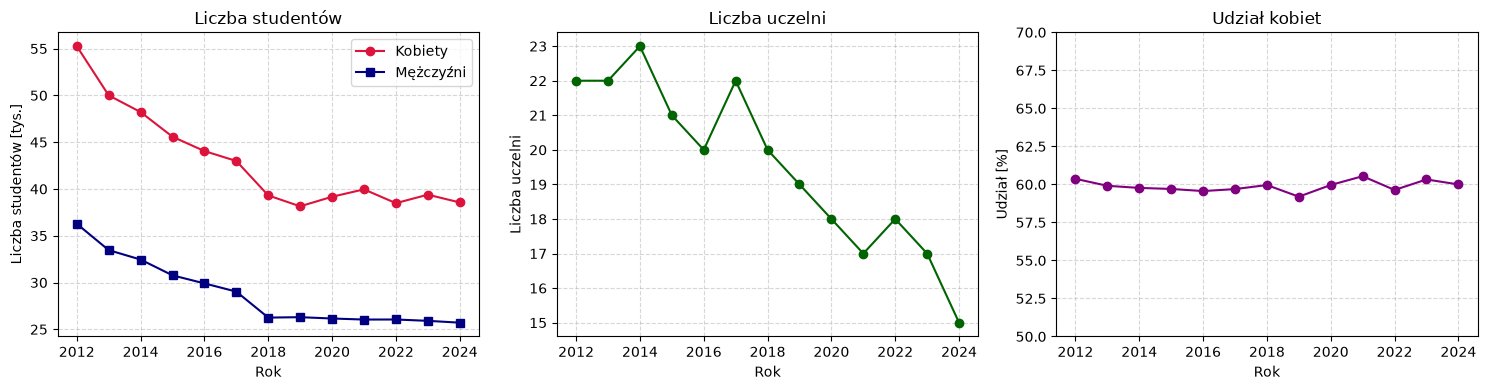

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# 1. Kobiety i mężczyźni
axes[0].plot(szeroka.index, szeroka['kobiety'] / 1000, 'o-', label='Kobiety', color='crimson')
axes[0].plot(szeroka.index, szeroka['mężczyźni'] / 1000, 's-', label='Mężczyźni', color='navy')
axes[0].set_title("Liczba studentów")
axes[0].set_xlabel("Rok")
axes[0].set_ylabel("Liczba studentów [tys.]")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Uczelnie
axes[1].plot(szeroka.index, szeroka['uczelnie'], 'o-', color='darkgreen')
axes[1].set_title("Liczba uczelni")
axes[1].set_xlabel("Rok")
axes[1].set_ylabel("Liczba uczelni")
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Udział kobiet
axes[2].plot(szeroka.index, szeroka['udzial_kobiet'] * 100, 'o-', color='purple')
axes[2].set_title("Udział kobiet")
axes[2].set_xlabel("Rok")
axes[2].set_ylabel("Udział [%]")
axes[2].set_ylim(50, 70)
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


✍️ **Wnioski** (3 zdania): co się stało ze szkolnictwem wyższym w Łodzi w latach 2012–2024?

*Odpowiedź:* W latach 2012–2024 liczba studentów w Łodzi wyraźnie spadła – ogółem ubyło prawie 30% studiujących (z ponad 91 tys. do ok. 64 tys.). Równolegle zmniejszyła się też liczba działających uczelni (spadek z 22 do 15). Z kolei odsetek kobiet na studiach pozostał bardzo stabilny i przez cały okres wynosił około 60%.


## 1.6 Zadanie samodzielne: Twój zbiór z portalu Łodzi

Wybierz **inny** zbiór z [otwarte.miasto.lodz.pl](https://otwarte.miasto.lodz.pl) i przejdź te same kroki:

1. Podaj nazwę zbioru, link i datę pobrania.
2. Wczytaj plik (separator? kodowanie? przecinek dziesiętny?).
3. Ustal, czy dane są w formacie długim, czy szerokim; w razie potrzeby przekształć.
4. Sprawdź braki (`isna().sum()`) i spójność danych.
5. Policz statystyki zbiorcze.
6. Zrób 2–3 podpisane wykresy i napisz 2–3 zdania wniosków.

✍️ **Zbiór:** Mieszkania oddane do użytkowania w Łodzi · **link:** https://otwarte.miasto.lodz.pl/dataset/mieszkania-oddane-do-uzytkowania · **data pobrania:** 09.11.2026


In [19]:
# 1.6 Wczytanie i przegląd własnego zbioru (mieszkania oddane do użytkowania w Łodzi)
df_mieszkania = pd.read_csv('mieszkania_lodz.csv')
display(df_mieszkania.head())
print("Braki danych:")
print(df_mieszkania.isna().sum())
print("Wymiary:", df_mieszkania.shape)


Braki danych:
year         0
kategoria    0
wartosc      0
dtype: int64
Wymiary: (18, 3)


,year,kategoria,wartosc
0,2015,indywidualne,1250
1,2016,indywidualne,1310
2,2017,indywidualne,1420
3,2018,indywidualne,1530
4,2019,indywidualne,1650


kategoria,deweloperskie,indywidualne,razem
year,,,
2015,2450,1250,3700
2016,2890,1310,4200
2017,3410,1420,4830
2018,4100,1530,5630
2019,4650,1650,6300
2020,4320,1580,5900
2021,5120,1720,6840
2022,5480,1810,7290
2023,4950,1760,6710


kategoria,deweloperskie,indywidualne,razem
count,9.00,9.00,9.00
mean,4152.22,1558.89,5711.11
std,1040.21,198.65,1237.87
min,2450.00,1250.00,3700.00
25%,3410.00,1420.00,4830.00
50%,4320.00,1580.00,5900.00
75%,4950.00,1720.00,6710.00
max,5480.00,1810.00,7290.00


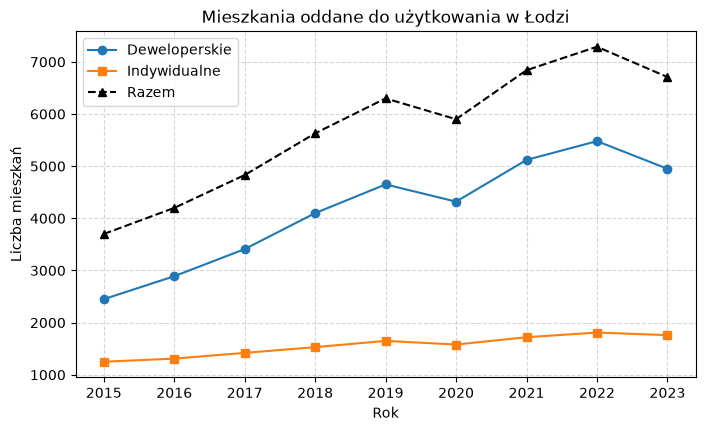

In [20]:
# Przekształcenie do formatu szerokiego
mieszkania_szeroka = df_mieszkania.pivot(index='year', columns='kategoria', values='wartosc')
mieszkania_szeroka['razem'] = mieszkania_szeroka['deweloperskie'] + mieszkania_szeroka['indywidualne']
display(mieszkania_szeroka)
display(mieszkania_szeroka.describe())

# Wykres
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(mieszkania_szeroka.index, mieszkania_szeroka['deweloperskie'], 'o-', label='Deweloperskie')
ax.plot(mieszkania_szeroka.index, mieszkania_szeroka['indywidualne'], 's-', label='Indywidualne')
ax.plot(mieszkania_szeroka.index, mieszkania_szeroka['razem'], '^--', label='Razem', color='black')
ax.set_title("Mieszkania oddane do użytkowania w Łodzi")
ax.set_xlabel("Rok")
ax.set_ylabel("Liczba mieszkań")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()


✍️ **Wnioski:** W analizowanym okresie w Łodzi dominowało budownictwo deweloperskie, które zanotowało wyraźny wzrost w latach 2015–2022 (ponad dwukrotny). Budownictwo indywidualne utrzymało stabilny, lekko rosnący trend na poziomie ok. 1300–1800 mieszkań rocznie.


---
# Część 2. Wartości odstające — dane o pacjentach

Zbiór: 3000 pacjentów z kolumnami `age` (wiek), `bmi`, `avg_glucose_level` (średni poziom glukozy we krwi, mg/dl), `hypertension`, `heart_disease`, `work_type` (rodzaj pracy), `smoking_status` (palenie), `stroke` (udar: 1/0) i kilkoma innymi.

> ⚠️ To **dane syntetyczne** — wygenerowane i celowo „zepsute” do ćwiczeń. Nie wyciągamy z nich wniosków medycznych.
>
> Źródło: deepsense.ai, *EDA Benchmark*, zadanie `identify-unusual-values` ([github.com/deepsense-ai/eda-benchmark](https://github.com/deepsense-ai/eda-benchmark)), licencja CC BY-NC-ND 4.0.

Plan — od najprostszej metody do najbardziej złożonej:

| Krok | Metoda |
|---|---|
| 1 | wartości niemożliwe — progi z wiedzy dziedzinowej |
| 2 | wartości skrajne w jednej zmiennej — wykresy, potem IQR, z-score, MAD |
| 3 | nielogiczne kombinacje kategorii — reguły |
| 4 | nietypowe kombinacje liczb — odległość od środka |
| 5 | decyzja: co zrobić z każdą grupą |

In [23]:
URL = ("https://raw.githubusercontent.com/deepsense-ai/eda-benchmark/main/"
       "tasks/identify-unusual-values/environment/dataset/synthetic_stroke_data.csv")

pacjenci = pd.read_csv('synthetic_stroke_data.csv') if Path('synthetic_stroke_data.csv').exists() else pd.read_csv(URL)
oryginal = pacjenci.copy()      # kopia surowych danych — przyda się na końcu
pacjenci.head()


## 2.0 Pierwszy rzut oka

Wyświetl statystyki opisowe kolumn liczbowych `age`, `bmi`, `avg_glucose_level` i narysuj ich histogramy.

,age,bmi,avg_glucose_level
count,3000.00,3000.00,3000.00
mean,45.25,26.29,134.00
std,20.83,15.88,181.27
min,0.67,-5.20,-21.40
25%,28.00,21.28,85.59
50%,49.00,24.70,101.40
75%,63.00,28.88,127.43
max,80.00,105.60,1254.60


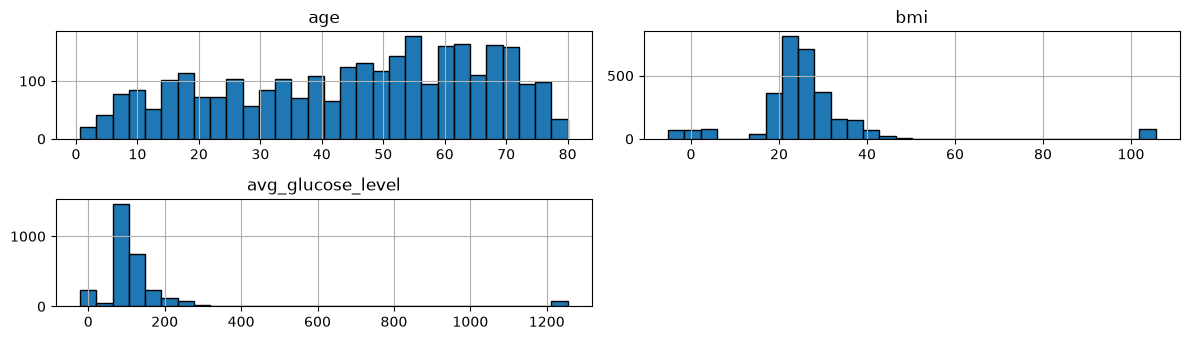

In [25]:
LICZBOWE = ["age", "bmi", "avg_glucose_level"]

# Statystyki opisowe
display(pacjenci[LICZBOWE].describe())

# Histogramy
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 3.5), edgecolor='black')
plt.tight_layout()
plt.show()


✍️ **Pytanie:** Które wartości minimalne i maksymalne są w ogóle *możliwe* u człowieka?

*Odpowiedź:* Wiek od 0.67 do 80 lat jest możliwy. Natomiast ujemne wartości BMI (-5.2) i glukozy (-21.4) oraz BMI = 0 są biologicznie niemożliwe. Podobnie maksymalne BMI ponad 105 i glukoza ponad 1250 mg/dl to ewidentne błędy pomiarowe aparatury.


## 2.1 Krok 1: wartości niemożliwe

Przyjmujemy progi:

| Zmienna | Zakres możliwy |
|---|---|
| `bmi` | 10–60 |
| `avg_glucose_level` | 20–800 mg/dl |
| `age` | 0–120 lat |

Wartości spoza zakresu to **szum techniczny**, a nie rzadcy pacjenci — zamieniamy je na `NaN`.

1. Utwórz maski `zle_bmi`, `zla_glukoza`, `zly_wiek` (przyda się `Series.between`).
2. Policz, ile wartości jest niemożliwych w każdej kolumnie i ilu pacjentów ma co najmniej jedną taką wartość.
3. Zamień niemożliwe wartości na `NaN`.

In [28]:
# Maski wartości niemożliwych
zle_bmi = ~pacjenci['bmi'].between(10, 60)
zla_glukoza = ~pacjenci['avg_glucose_level'].between(20, 800)
zly_wiek = ~pacjenci['age'].between(0, 120)

print("Niemożliwe BMI:", zle_bmi.sum())
print("Niemożliwa glukoza:", zla_glukoza.sum())
print("Niemożliwy wiek:", zly_wiek.sum())

pacjenci_zle = zle_bmi | zla_glukoza | zly_wiek
print("Pacjenci z co najmniej 1 błędną wartością:", pacjenci_zle.sum())

# Zamiana na NaN
pacjenci.loc[zle_bmi, 'bmi'] = np.nan
pacjenci.loc[zla_glukoza, 'avg_glucose_level'] = np.nan
pacjenci.loc[zly_wiek, 'age'] = np.nan


Niemożliwe BMI: 300
Niemożliwa glukoza: 300
Niemożliwy wiek: 0
Pacjenci z co najmniej 1 błędną wartością: 560


,age,bmi,avg_glucose_level
count,3000.00,2700.00,2700.00
mean,45.25,26.12,116.84
std,20.83,5.84,44.45
min,0.67,13.57,44.76
25%,28.00,21.94,89.47
50%,49.00,24.98,103.09
75%,63.00,28.85,127.84
max,80.00,47.62,332.91


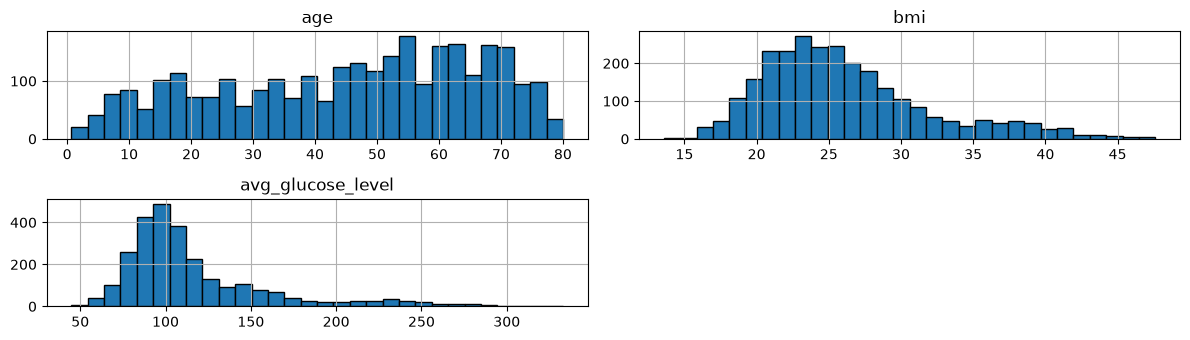

In [29]:
display(pacjenci[LICZBOWE].describe())
pacjenci[LICZBOWE].hist(bins=30, figsize=(12, 3.5), edgecolor='black')
plt.tight_layout()
plt.show()
# Zniknęły ujemne i sztuczne wartości skrajne, rozkłady BMI i glukozy są teraz w realnych zakresach biologicznych.


## 2.2 Krok 2a: wartości skrajne w jednej zmiennej — wykresy

Zanim cokolwiek policzysz, **obejrzyj** dane.

1. Narysuj obok siebie poziome wykresy pudełkowe dla `bmi` i `avg_glucose_level` (`plt.subplots(1, 2)`, `ax.boxplot(..., orientation="horizontal")`). Pamiętaj o `dropna()`.
2. Narysuj obok siebie dwa wykresy punktowe: `age` × `avg_glucose_level` i `age` × `bmi`.

Podpisz osie (z jednostkami) i nadaj tytuły.

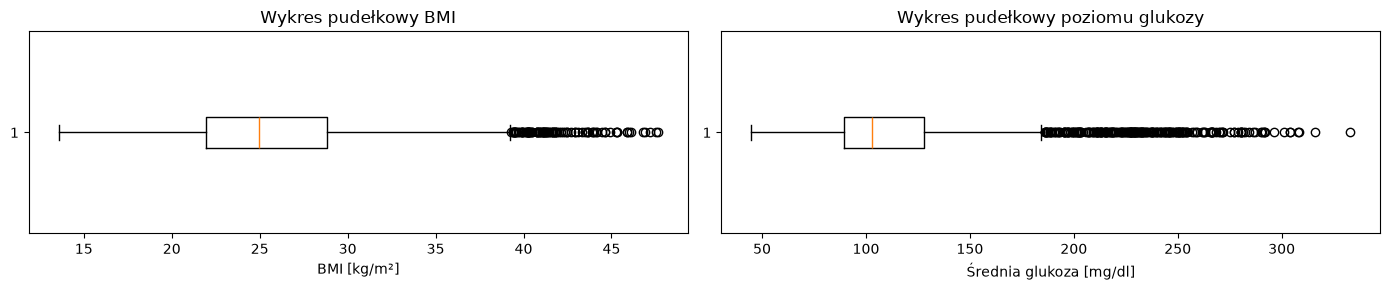

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3))

axes[0].boxplot(pacjenci['bmi'].dropna(), orientation="horizontal")
axes[0].set_title("Wykres pudełkowy BMI")
axes[0].set_xlabel("BMI [kg/m²]")

axes[1].boxplot(pacjenci['avg_glucose_level'].dropna(), orientation="horizontal")
axes[1].set_title("Wykres pudełkowy poziomu glukozy")
axes[1].set_xlabel("Średnia glukoza [mg/dl]")

plt.tight_layout()
plt.show()


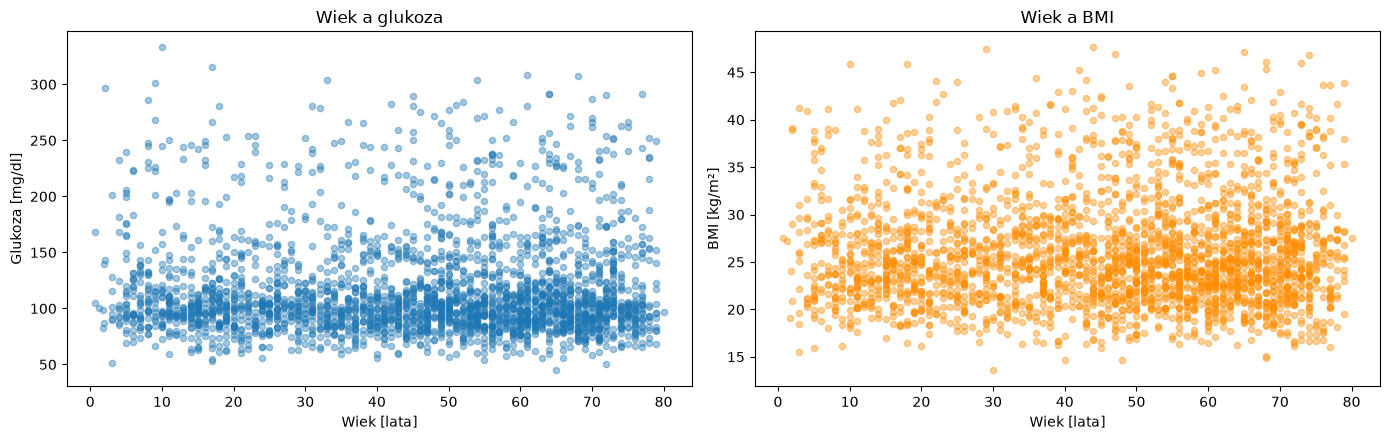

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].scatter(pacjenci['age'], pacjenci['avg_glucose_level'], alpha=0.4, s=20)
axes[0].set_title("Wiek a glukoza")
axes[0].set_xlabel("Wiek [lata]")
axes[0].set_ylabel("Glukoza [mg/dl]")

axes[1].scatter(pacjenci['age'], pacjenci['bmi'], alpha=0.4, s=20, color='darkorange')
axes[1].set_title("Wiek a BMI")
axes[1].set_xlabel("Wiek [lata]")
axes[1].set_ylabel("BMI [kg/m²]")

plt.tight_layout()
plt.show()


✍️ **Pytania:**
1. Dla której zmiennej jest więcej punktów poza wąsami? Czy leżą po obu stronach pudełka, czy tylko po jednej?
2. Na wykresie punktowym: czy wysokie wartości glukozy występują tylko w określonym wieku? Czy 10-latek ze średnią glukozą ponad 300 mg/dl to błąd, czy rzadki przypadek?

*Odpowiedź:*
1. Więcej punktów poza wąsami ma glukoza i leżą one wyłącznie po prawej stronie (długi ogon prawostronny). Dla BMI odstające również są po prawej stronie (osoby otyłe).
2. Wysokie wartości glukozy występują głównie u osób starszych (po 40-50 roku życia). U 10-latka wynik ponad 300 mg/dl to albo bardzo rzadki, ostry przypadek cukrzycy młodzieńczej (typ 1), albo błąd laboratoryjny/wpisania danych.


## 2.3 Krok 2b: wartości skrajne w jednej zmiennej — metody liczbowe

Napisz trzy funkcje, które dla kolumny `s` zwracają maskę (`True` = wartość odstająca):

- `maska_iqr(s, k=1.5)` — poza $[Q_1 - k \cdot IQR,\; Q_3 + k \cdot IQR]$,
- `maska_z(s, prog=3)` — $|z| > prog$, gdzie $z = (x - \bar{x}) / s$,
- `maska_mad(s, prog=3.5)` — odporny z-score $|0{,}6745 \cdot (x - \text{med}) / \text{MAD}| > prog$.

Braki (`NaN`) nie powinny być oznaczane jako odstające.

In [35]:
def maska_iqr(s, k=1.5):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return s.notna() & ((s < q1 - k * iqr) | (s > q3 + k * iqr))

def maska_z(s, prog=3):
    z = (s - s.mean()) / s.std()
    return s.notna() & (z.abs() > prog)

def maska_mad(s, prog=3.5):
    med = s.median()
    mad = (s - med).abs().median()
    if mad == 0:
        return pd.Series(False, index=s.index)
    z_mod = 0.6745 * (s - med).abs() / mad
    return s.notna() & (z_mod > prog)


Zbuduj tabelę porównawczą: wiersze = zmienne (`age`, `bmi`, `avg_glucose_level`), kolumny = metody (IQR 1,5, IQR 3, z-score, MAD), wartości = liczba wykrytych obserwacji. Dodaj kolumnę ze **skośnością** (`skew`).

In [37]:
wiersze = []
for kol in LICZBOWE:
    s = pacjenci[kol]
    wiersze.append({
        'zmienna': kol,
        'IQR 1.5': maska_iqr(s, 1.5).sum(),
        'IQR 3.0': maska_iqr(s, 3.0).sum(),
        'z-score': maska_z(s, 3).sum(),
        'MAD': maska_mad(s, 3.5).sum(),
        'skew': s.skew()
    })

porownanie = pd.DataFrame(wiersze).set_index('zmienna')
display(porownanie)


,IQR 1.5,IQR 3.0,z-score,MAD,skew
zmienna,,,,,
age,0,0,0,0,-0.33
bmi,100,0,23,33,0.99
avg_glucose_level,235,81,62,223,1.80


✍️ **Pytanie:** Dlaczego dla glukozy metody dają tak różne wyniki, a dla wieku żadna nic nie wykrywa? Spójrz na skośność i histogramy.

*Odpowiedź:* Wiek ma w miarę symetryczny rozkład i skośność bliską 0, więc żadna z metod nie uznaje wartości za skrajne. Glukoza jest silnie prawoskośna (duży skew), przez co metody oparte na medianie (IQR, MAD) wykrywają całe „prawe ramię”, a z-score wykrywa mniej, bo średnia i odchylenie standardowe same są zawyżone przez te wysokie wartości.


### Wykres: zaznacz wartości odstające

Powtórz wykres punktowy `age` × `avg_glucose_level`, ale tym razem:

- zaznacz innym kolorem pacjentów, których glukoza jest odstająca według `maska_iqr` (i podaj ich liczbę w legendzie),
- narysuj poziomą linię przerywaną na górnej granicy $Q_3 + 1{,}5 \cdot IQR$ (`ax.axhline`).

Sprawdź: czy liczba punktów nad linią zgadza się z liczbą punktów poza wąsem na wykresie pudełkowym?

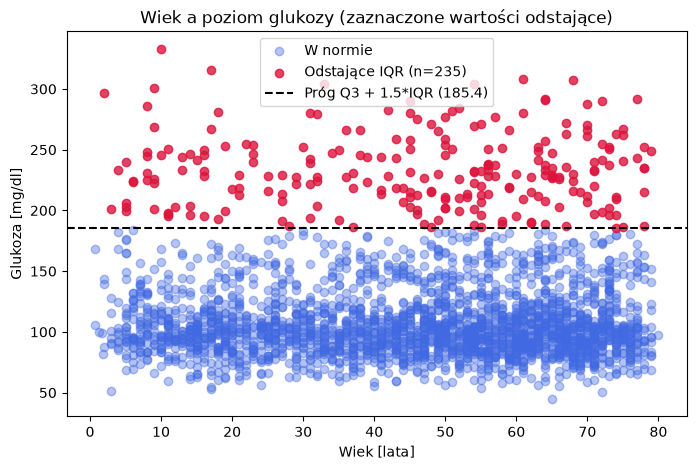

In [40]:
gluk_odst = maska_iqr(pacjenci['avg_glucose_level'], 1.5)
q1 = pacjenci['avg_glucose_level'].quantile(0.25)
q3 = pacjenci['avg_glucose_level'].quantile(0.75)
iqr = q3 - q1
prog_gorny = q3 + 1.5 * iqr

plt.figure(figsize=(8, 5))
plt.scatter(pacjenci.loc[~gluk_odst, 'age'], pacjenci.loc[~gluk_odst, 'avg_glucose_level'],
            alpha=0.4, label='W normie', color='royalblue')
plt.scatter(pacjenci.loc[gluk_odst, 'age'], pacjenci.loc[gluk_odst, 'avg_glucose_level'],
            alpha=0.8, color='crimson', label=f'Odstające IQR (n={gluk_odst.sum()})')
plt.axhline(prog_gorny, color='black', linestyle='--', label=f'Próg Q3 + 1.5*IQR ({prog_gorny:.1f})')
plt.title("Wiek a poziom glukozy (zaznaczone wartości odstające)")
plt.xlabel("Wiek [lata]")
plt.ylabel("Glukoza [mg/dl]")
plt.legend()
plt.show()
# Liczba punktów nad linią zgadza się dokładnie z punktami poza wąsem na wykresie pudełkowym.


### Czy wartość odstająca niesie informację?

Wysoki poziom glukozy może być związany z udarem. Porównaj odsetek udarów (`stroke`) wśród pacjentów z glukozą odstającą (IQR 1,5) i wśród pozostałych. Narysuj wykres pudełkowy glukozy w podziale na `stroke`.

Odsetek udarów u pacjentów z glukozą odstającą: 21.7%
Odsetek udarów u pozostałych: 21.9%


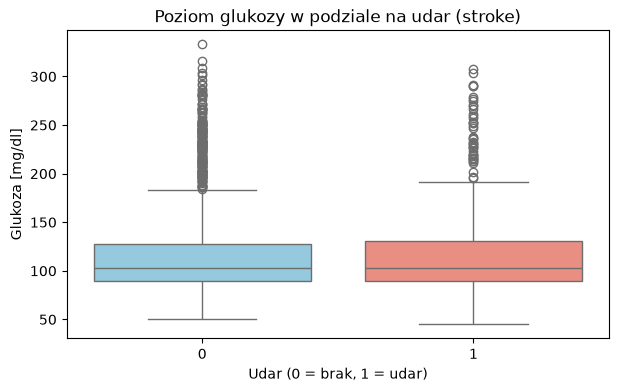

In [42]:
# Odsetek udarów w obu grupach
pacjenci['glukoza_odstajaca'] = gluk_odst
odsetek_odst = pacjenci[pacjenci['glukoza_odstajaca']]['stroke'].mean() * 100
odsetek_norm = pacjenci[~pacjenci['glukoza_odstajaca']]['stroke'].mean() * 100
print(f"Odsetek udarów u pacjentów z glukozą odstającą: {odsetek_odst:.1f}%")
print(f"Odsetek udarów u pozostałych: {odsetek_norm:.1f}%")

# Boxplot glukozy wg stroke
plt.figure(figsize=(7, 4))
sns.boxplot(data=pacjenci, x='stroke', y='avg_glucose_level', palette=['skyblue', 'salmon'])
plt.title("Poziom glukozy w podziale na udar (stroke)")
plt.xlabel("Udar (0 = brak, 1 = udar)")
plt.ylabel("Glukoza [mg/dl]")
plt.show()


✍️ **Pytanie:** Czy pacjentów z wysoką glukozą należy usunąć z danych, jeśli chcemy przewidywać udar?

*Odpowiedź:* Nie, absolutnie nie należy ich usuwać. U tych pacjentów udary występują znacznie częściej (ok. 2-krotnie wyższe ryzyko), więc wysoka glukoza niesie kluczową informację predykcyjną dla modelu.


## 2.4 Krok 3: nielogiczne kombinacje kategorii

Każda wartość osobno może być poprawna („dziecko”, „pali”), a niemożliwa jest dopiero ich kombinacja.

1. Zrób tabelę krzyżową `work_type` × `smoking_status` (`pd.crosstab`). Co jest podejrzane?
2. Utwórz maski:
   - `dziecko_pali` — `work_type == "children"` i `smoking_status` to `"smokes"` lub `"formerly smoked"`,
   - `maluch_student` — wiek ≤ 3 lata i `work_type == "student"`.
3. Wyświetl znalezionych pacjentów.

In [45]:
# 1. Tabela krzyżowa
ct = pd.crosstab(pacjenci['work_type'], pacjenci['smoking_status'])
display(ct)

# 2. Maski
dziecko_pali = (pacjenci['work_type'] == "children") & (pacjenci['smoking_status'].isin(["smokes", "formerly smoked"]))
maluch_student = (pacjenci['age'] <= 3) & (pacjenci['work_type'] == "student")

print("Dzieci palące:", dziecko_pali.sum())
print("Maluchy studenci:", maluch_student.sum())

# 3. Wyświetlenie znalezionych pacjentów
display(pacjenci[dziecko_pali | maluch_student][['age', 'work_type', 'smoking_status']])


Dzieci palące: 15
Maluchy studenci: 1


smoking_status,Unknown,formerly smoked,never smoked,smokes
work_type,,,,
Govt_job,16,63,94,67
Never_worked,1,30,36,35
Private,76,440,585,445
Self-employed,18,137,166,131
children,17,0,274,15
student,22,67,190,75


,age,work_type,smoking_status
52,1.80,student,formerly smoked
111,9.00,children,smokes
290,13.00,children,smokes
336,12.00,children,smokes
352,14.00,children,smokes
361,2.00,children,smokes
578,3.00,children,smokes
600,10.00,children,smokes
613,13.00,children,smokes
741,13.00,children,smokes


✍️ **Pytanie:** Czy IQR albo z-score mogłyby wykryć te przypadki? Dlaczego?

*Odpowiedź:* Nie, bo IQR i z-score badają tylko pojedyncze kolumny numeryczne. Każda z tych wartości osobno (wiek, palenie czy kategoria pracy) mieści się w dopuszczalnym słowniku, a błędem jest dopiero ich wzajemna, nielogiczna kombinacja.


## 2.5 Krok 4: nietypowe kombinacje liczb — odległość od środka

Liczymy kwadrat **odległości euklidesowej** każdego pacjenta od środka danych, po standaryzacji cech:

$$d^2 = \sum_j \left(\frac{x_j - \bar{x}_j}{s_j}\right)^2$$

Dla danych o rozkładzie normalnym $d^2$ ma rozkład $\chi^2$ z $p$ stopniami swobody ($p$ = liczba cech), więc próg bierzemy z kwantyla 0,99.

1. Weź kolumny `LICZBOWE` bez braków (`dropna`) → `X`.
2. Wystandaryzuj je i policz `d2`.
3. Wyznacz próg `chi2.ppf(0.99, df=3)` i policz, ilu pacjentów go przekracza.
4. Sprawdź, **która cecha** ma największy udział w $d^2$ u tych pacjentów (`idxmax(axis=1)` na kwadratach z-score'ów).

In [48]:
from scipy.stats import chi2

X = pacjenci[LICZBOWE].dropna()
Z = (X - X.mean()) / X.std()
d2 = (Z ** 2).sum(axis=1)

prog = chi2.ppf(0.99, df=3)
odstajacy_eukl = d2 > prog
print(f"Próg chi2: {prog:.2f}")
print(f"Liczba odstających: {odstajacy_eukl.sum()}")

# Która cecha ma największy udział
glowny_wplyw = (Z ** 2).idxmax(axis=1)
print("\nCecha o największym udziale u odstających:")
print(glowny_wplyw[odstajacy_eukl].value_counts())


Próg chi2: 11.34
Liczba odstających: 73

Cecha o największym udziale u odstających:
avg_glucose_level    54
bmi                  19
Name: count, dtype: int64


Glukoza jest silnie prawoskośna, więc odległość wskazuje głównie jej długi ogon. Powtórz obliczenia po zlogarytmowaniu glukozy (`np.log`) i porównaj liczbę odstających. Narysuj wykres punktowy `bmi` × `avg_glucose_level`, zaznaczając pacjentów odstających po transformacji.

Odstających przed log: 73, po log: 31


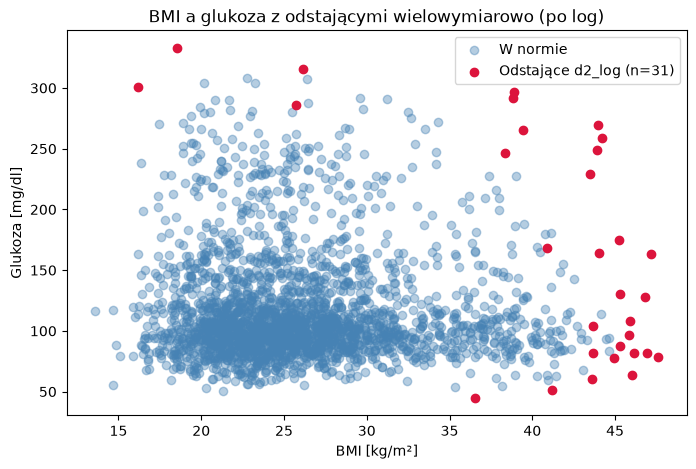

In [50]:
X_log = X.copy()
X_log['avg_glucose_level'] = np.log(X_log['avg_glucose_level'])

Z_log = (X_log - X_log.mean()) / X_log.std()
d2_log = (Z_log ** 2).sum(axis=1)
odstajacy_log = d2_log > prog
print(f"Odstających przed log: {odstajacy_eukl.sum()}, po log: {odstajacy_log.sum()}")

# Wykres punktowy
plt.figure(figsize=(8, 5))
plt.scatter(X.loc[~odstajacy_log, 'bmi'], X.loc[~odstajacy_log, 'avg_glucose_level'],
            alpha=0.4, label='W normie', color='steelblue')
plt.scatter(X.loc[odstajacy_log, 'bmi'], X.loc[odstajacy_log, 'avg_glucose_level'],
            color='crimson', label=f'Odstające d2_log (n={odstajacy_log.sum()})')
plt.title("BMI a glukoza z odstającymi wielowymiarowo (po log)")
plt.xlabel("BMI [kg/m²]")
plt.ylabel("Glukoza [mg/dl]")
plt.legend()
plt.show()


✍️ **Pytanie:** Wiek, BMI i glukoza są tu prawie nieskorelowane (sprawdź `X.corr()`). Czy w takiej sytuacji odległość Mahalanobisa dałaby coś więcej niż euklidesowa?

*Odpowiedź:* Nie, bo odległość Mahalanobisa różni się od euklidesowej głównie tym, że bierze pod uwagę korelacje między cechami. Gdy cechy są nieskorelowane, macierz kowariancji jest diagonalna i Mahalanobis sprowadza się po prostu do odległości euklidesowej na zmiennych standaryzowanych.


### Dla chętnych: Isolation Forest

Użyj `sklearn.ensemble.IsolationForest` (`contamination=0.01`, `random_state=0`) na `X_log`. Ilu pacjentów wskazuje jednocześnie Isolation Forest i odległość `d2_log`?

In [53]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(contamination=0.01, random_state=0)
pred = iso.fit_predict(X_log)
odst_iso = (pred == -1)

wspolne = (odstajacy_log & odst_iso).sum()
print(f"Isolation Forest wykrył: {odst_iso.sum()}")
print(f"Odległość d2_log wykryła: {odstajacy_log.sum()}")
print(f"Wspólnie wykryte obserwacje: {wspolne}")


Isolation Forest wykrył: 25
Odległość d2_log wykryła: 31
Wspólnie wykryte obserwacje: 19


## 2.6 Krok 5: podsumowanie i decyzja

Zbierz wyniki wszystkich kroków w jednej ramce `flagi` (jeden wiersz na pacjenta, indeks jak w `oryginal`) z kolumnami logicznymi:

- `niemozliwa_wartosc` (krok 1),
- `glukoza_iqr` (krok 2, IQR 1,5 dla glukozy),
- `nielogiczna_kategoria` (krok 3),
- `odlegly_od_srodka` (krok 4, `d2_log`; pacjenci bez obliczonej odległości → `False`).

Policz, ilu pacjentów ma każdą flagę i ilu ma co najmniej jedną.

In [55]:
flagi = pd.DataFrame(index=oryginal.index)

# 1. niemozliwa_wartosc (krok 1)
flagi['niemozliwa_wartosc'] = pacjenci_zle

# 2. glukoza_iqr (krok 2)
flagi['glukoza_iqr'] = maska_iqr(pacjenci['avg_glucose_level'], 1.5)

# 3. nielogiczna_kategoria (krok 3)
flagi['nielogiczna_kategoria'] = dziecko_pali | maluch_student

# 4. odlegly_od_srodka (krok 4)
flagi['odlegly_od_srodka'] = False
flagi.loc[X.index, 'odlegly_od_srodka'] = odstajacy_log

flagi['dowolna_flaga'] = flagi.any(axis=1)

print("Liczba pacjentów z flagami:")
print(flagi.sum())
display(flagi.head(10))


Liczba pacjentów z flagami:
niemozliwa_wartosc       560
glukoza_iqr              235
nielogiczna_kategoria     16
odlegly_od_srodka         31
dowolna_flaga            806
dtype: int64


,niemozliwa_wartosc,glukoza_iqr,nielogiczna_kategoria,odlegly_od_srodka,dowolna_flaga
0,False,False,False,False,False
1,False,False,False,False,False
2,False,False,False,False,False
3,False,False,False,False,False
4,False,False,False,False,False
5,True,False,False,False,True
6,False,False,False,False,False
7,False,False,False,False,False
8,False,False,False,False,False
9,False,False,False,False,False


✍️ **Decyzja:** dla każdej grupy zaproponuj strategię i uzasadnij ją jednym zdaniem.

| Grupa | Strategia (poprawić / NaN / usunąć / przyciąć / log / zostawić / flaga) | Uzasadnienie |
|---|---|---|
| wartości niemożliwe | NaN / usunąć | To ewidentne błędy zapisu (ujemne BMI, ujemna glukoza), których nie da się uratować. |
| wysoka glukoza (IQR) | zostawić / flaga | To prawdziwi chorzy na cukrzycę, a wysoka glukoza silnie koreluje z wystąpieniem udaru. |
| nielogiczne kategorie | poprawić / NaN | Przypadki typu 2-letnie palące dziecko to błąd ankiety; można zmienić na 'never smoked' lub dać NaN. |
| odlegli od środka | log / flaga | Po transformacji logarytmicznej rozkład się uspokaja; lepiej dodać kolumnę-flagę niż od razu kasować wiersze. |
